# Question 1 (core):

For an object with mass $m$ attached to a spring with spring constant $k$ that is undergoing simple oscillation, we can write its equation of motion as : $m\ddot{x} = -kx$, where the natural frequency is given by $\omega = \sqrt{k/m}$, the position of the object is given by $x = r$, the velocity of the object is given by $\dot{x} = v$ and the acceleration of the object is given by $\ddot{x} = a$. After solving this ODE, we obtain the general solutions for the position and the velocity of the object in terms of time $t$:

\begin{align}
r(t) &= C_1 \cos(\omega t) + C_2 \sin(\omega t) \\
v(t) &= C_2 \omega \cos(\omega t) - C_1 \omega \sin(\omega t) 
\end{align}

where $C_1$ and $C_2$ are arbitrary constants to be determined by initial conditions.

Assuming the initial conditions are $r(0) = r_0 , v(0) = v_0 ,$  we can find the particular solutions for both the position and the velocity:

\begin{align}
r(t) &= r_0 \cos(\omega t) + \frac{v_0}{\omega} \sin(\omega t) \\
v(t) &= v_0 \cos(\omega t) - r_0 \omega \sin(\omega t) 
\end{align}


And we can calculate the position and the velocity of an object at time $t$ by setting the parameters values for $ m, k, r_0, v_0, t$ accordingly using the function below:

In [1]:
import numpy as np

def position_velocity_exact (m, k, r0, v0,t):
    """
    This function takes 5 inputs that specifies the parameter values in the order 
    of: Mass(m), Spring Constant(k), Initial Position(r0), Initial Velocity(v0) and Time(t),
    and it returns the exact postion and the exact velocity of an object that is in simple oscillations
    with the input parameters at time t.
    """
    
    w = np.sqrt(k/m)
    r_exact = r0*np.cos(w*t) + (v0/w)*np.sin(w*t)
    v_exact = v0*np.cos(w*t) - r0*w*np.sin(w*t)

    return float(r_exact), float(v_exact)

print("Demonstartion: The exact position and the velocity of an object with mass 1 kg, spring constant 2, initial position 3 m, initial velocity 4 m/s at time 5 s is " + str(position_velocity_exact (1,2,3,4,5)))

Demonstartion: The exact position and the velocity of an object with mass 1 kg, spring constant 2, initial position 3 m, initial velocity 4 m/s at time 5 s is (4.121006224442668, -0.18605213304224488)


Alternatively, we can use the velocity Verlet algorithm to solve the same ODE. As stated above, the acceleration is given by $\ddot{x} = a = -\frac{kx}{m}$, and thus we can apply the algorithm:

\begin{align}
r_{n+1} &= r_n + v_n\,dt + \frac{1}{2}a(r_n)\,dt^2 \\
v_{n+1} &= v_n + \frac{1}{2}\left(a(r_n) + a(r_{n+1})\right)dt
\end{align}

where $r = x$, $v = \dot{r} = \dot{x}$, $dt$ is the time step, and $r_n$ and $v_n$ are the position and velocity of the object after $n$ steps, i.e. at time $t = n\,dt$. Substituting in the acceleration gives:

\begin{align}
r_{n+1} &= r_n + v_n\,dt - \frac{k}{2m}r_n\,dt^2 \\
v_{n+1} &= v_n - \frac{k}{2m}\left(r_n + r_{n+1}\right)dt
\end{align}

At each step the position $r_{n+1}$ must be calculated first, since the velocity update requires the acceleration at the new position. Starting with the initial conditions $x_0 = r_0$ and $v_0$ and repeating this for $N = t/dt$ steps gives approximations of the position and velocity at time $t$. We can calculate these using the function below:

In [2]:
def position_velocity_verlet (m,k, r0, v0, dt, N):
   
    """
    This function takes 6 inputs that specifies the parameter values in the order 
    of: Mass(m), Spring Constant(k), Initial Position(r0), Initial Velocity(v0), Time step(dt) and 
    Total Step Number (N) and it uses the velocity Verlet algorithm to approximate the postion and velocity of an object 
    that is in simple oscillations with the input parameters at the Nth step.
    """

    r = r0
    v = v0

    for n in range(N):
        r_new = r + (v * dt) - ((k * r / (2*m)) * (dt**2))
        v = v - k*(r + r_new) * dt/ (2 *m)
        r = r_new
        
    return float(r) , float (v)

print("Demonstartion: The position and the velocity of an object with mass 6 kg, spring constant 7, initial position 8 m, initial velocity 9 m/s approximated using the velocity Verlet algorithm with time step 0.1 at the 300th step is " + str(position_velocity_verlet (6,7,8,9,0.1,300)))


Demonstartion: The position and the velocity of an object with mass 6 kg, spring constant 7, initial position 8 m, initial velocity 9 m/s approximated using the velocity Verlet algorithm with time step 0.1 at the 300th step is (11.33616011029688, -2.441221236370682)


To see how the exact solutions differs from the Verlet approximations, we can plot and compare the position/time graph, $(t,x(t)=r(t))$ and the phase space trajectories $(x(t)=r(t),v(t))$ generated by both mehtods, using the functions below:

Demonstartion: The position/time graph and the phase space trajectories of an object in simple oscillation with mass 5 kg, spring constant 1, initial position 7 m, initial velocity 3 m/s generated using the velocity Verlet algorithm with time step 1.16 and the exact soulution up till the time 25 s are shown as below:


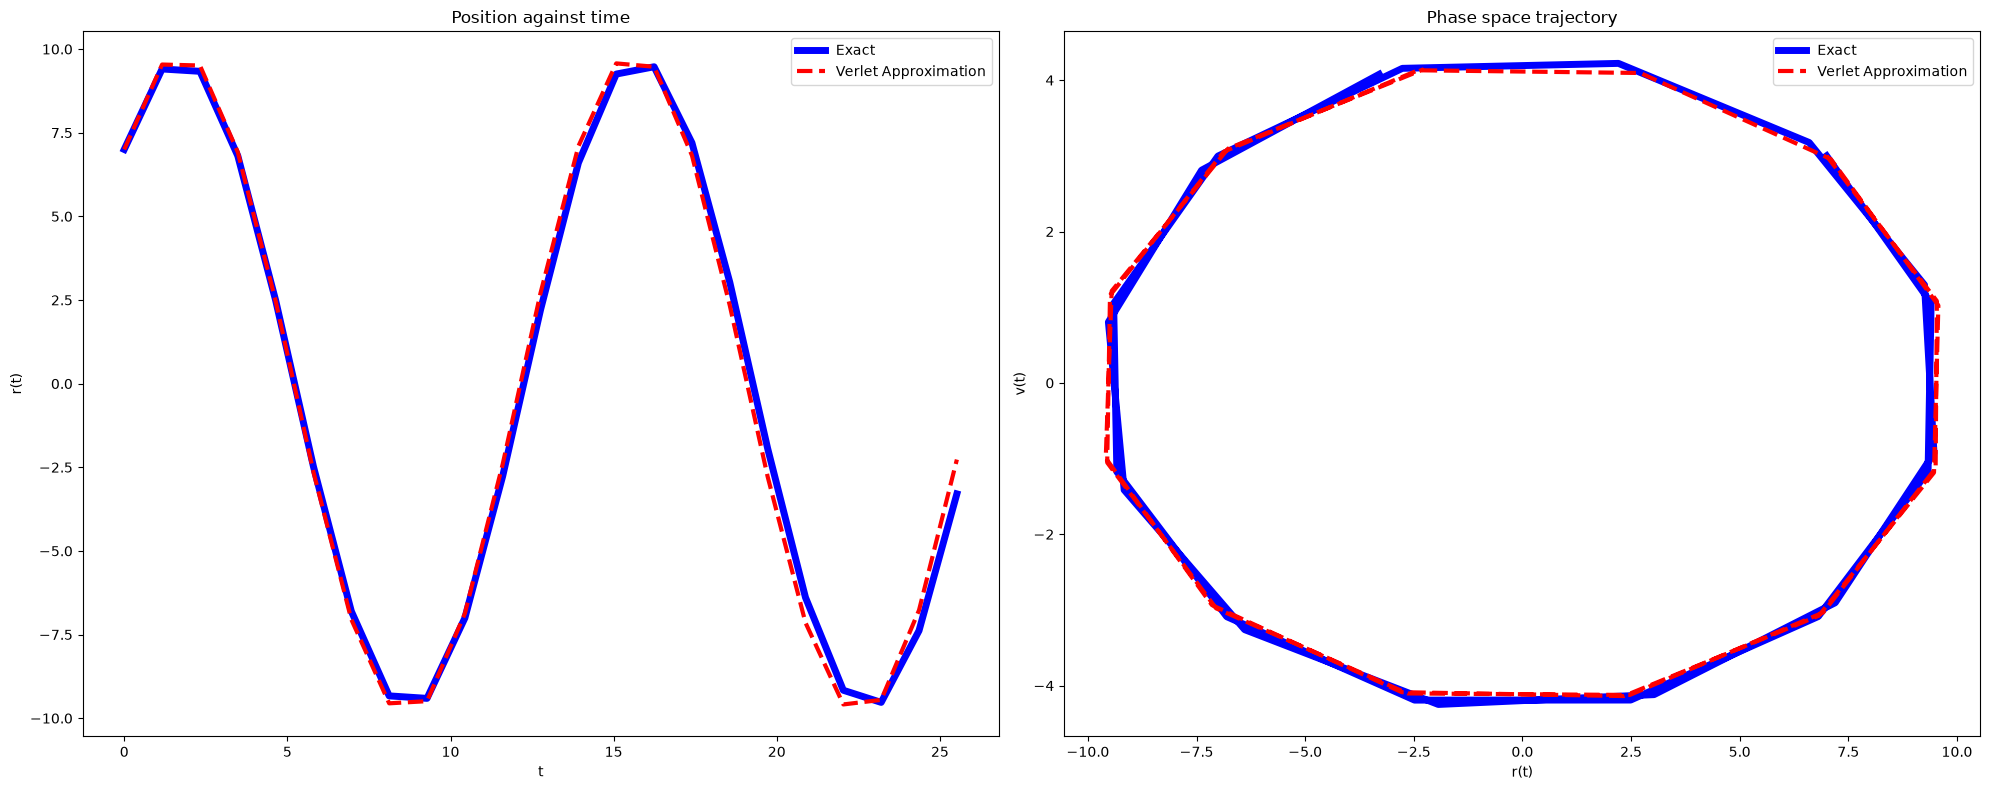

In [3]:
import matplotlib.pyplot as plt

def plot_compare(m,k, r0, v0, dt, t):
    """
    This function implements the 2 different methods to generate lists of position and velocity data of an object 
    that is in simple oscillations with the input parameters at the Nth step / time t using the function above and 
    plots the position/time graph and the phase space trajectories for each computation method on the same diagram
    as the output for comparison.
    """

    N = round(t/dt)
    time_at_steps = np.linspace(0, dt*N, N+1)
    r_exact = []
    v_exact = []
    r_verlet = []
    v_verlet = []

    for n in range(N+1):
        exact_r, exact_v = position_velocity_exact (m, k, r0, v0,time_at_steps[n])
        verlet_r, verlet_v = position_velocity_verlet (m,k, r0, v0, dt, n)
        r_exact.append(exact_r)
        v_exact.append(exact_v)
        r_verlet.append(verlet_r)
        v_verlet.append(verlet_v)

    fig, ax = plt.subplots(1, 2, figsize = (20,8))

    ax[0].plot(time_at_steps, r_exact, color = "blue", linewidth = 5, label = 'Exact')
    ax[0].plot(time_at_steps, r_verlet, "--", color = "red", linewidth = 3, label = 'Verlet Approximation')
    ax[0].set(xlabel="t", ylabel = "r(t)", title = "Position against time")
    ax[0].legend()
    ax[1].plot(r_exact, v_exact, color = "blue", linewidth = 5, label = 'Exact')
    ax[1].plot(r_verlet, v_verlet, "--",  color = "red", linewidth = 3, label = 'Verlet Approximation')
    ax[1].set(xlabel="r(t)", ylabel = "v(t)", title = "Phase space trajectory")
    ax[1].legend()

    plt.tight_layout()
    plt.show()

    return


print("Demonstartion: The position/time graph and the phase space trajectories of an object in simple oscillation with mass 5 kg, spring constant 1, initial position 7 m, initial velocity 3 m/s generated exactly as well as using the velocity Verlet algorithm with time step 1.16 till the time 25 s are shown as below:")
plot_compare(5,1,7,3,1.16,25)

If we set specific parameters for our objects, we can now compare the numerical solution with the exact solution on the Python generated plot and see the difference between the 2 methods of computation. For example, if we use an object with mass $6 kg$, spring constant 2, initial position $8 m$, initial velocity $4 m/s$, and choose the time step as 0.9 with the total time $30 s$, the 2 plots we obtain are as follows:

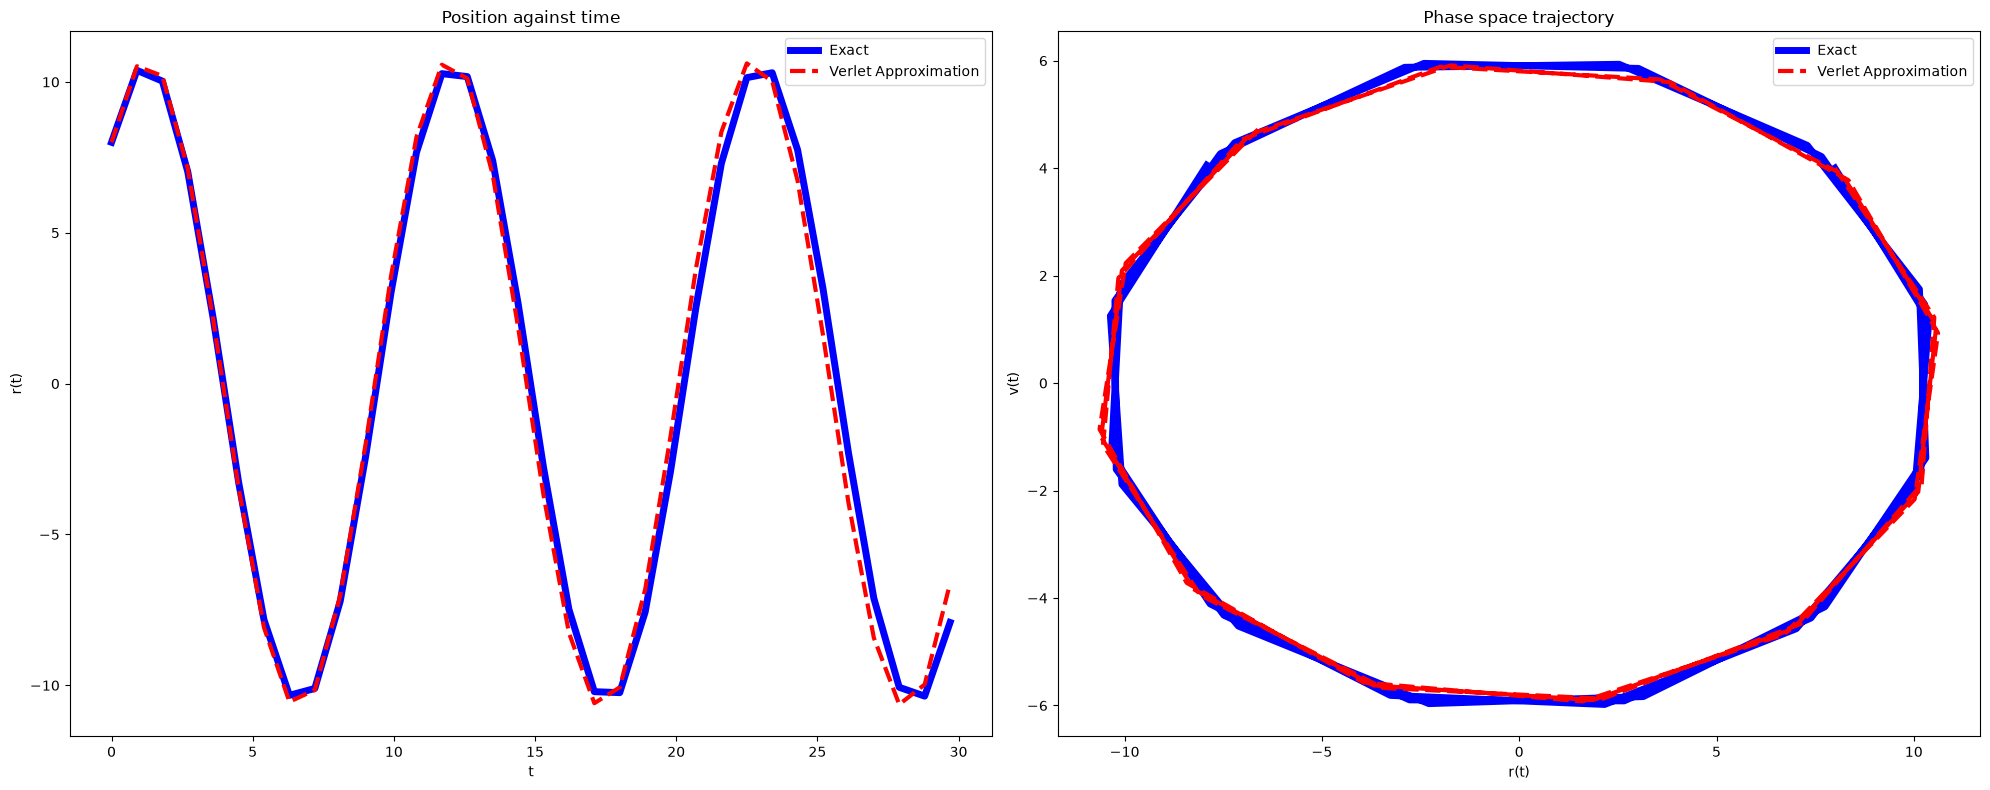

In [4]:
plot_compare(6,2,8,4,0.9,30)

The blue lines represent the exact solutions while the red dotted line represent the Verlet Approximation, and both graphs clearly shows that there is a noticable difference between the 2 lines given the set parameters. However, if we use the same set of parameters, but instead choose a much smaller time step, e.g. 0.09 instead of 0.9, the difference we would observe become much smaller, as shown below:

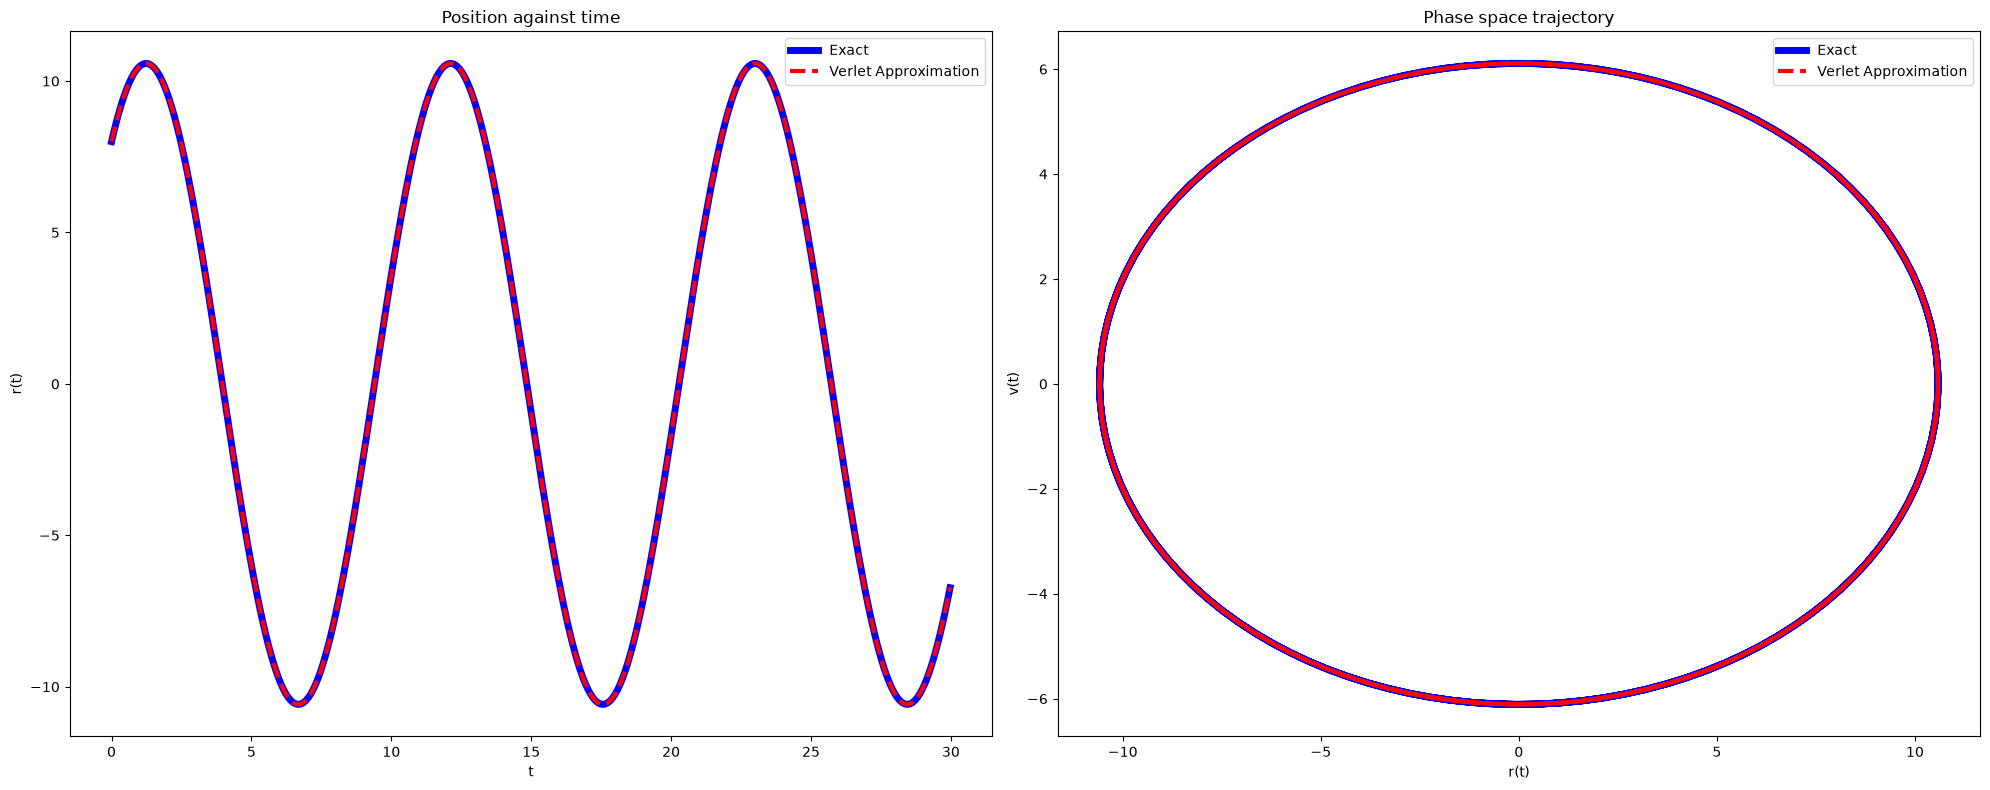

In [5]:
plot_compare(6,2,8,4,0.09,30)

We can see that in both graphs, the 2 lines basically overlap each other, which means that if the time step is reasonably small, the velocity Verlot algorithm become indistinguishable in practice from the exact solution for simple oscillations.